# Golden Standard Feature Statistics

Analysis of feature distributions for high-confidence cell pairings.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
import torch

%matplotlib inline

from cell_matching_utils import (
    load_cells_from_csv_files,
    dtw_distance_gpu_single,
    get_cluster_cells,
    compute_ot_cost_matrix,
    solve_optimal_transport,
    DTW_NORM_DIVISOR,
    OT_NORM_DIVISOR
)

import cell_matching_utils as recon_module

In [2]:
def solve_ot_with_adaptive_reg(C, weights_a, weights_b):
    adaptive_reg = max(np.max(C) / 10.0, 50000.0)
    original_reg = recon_module.SINKHORN_REG
    recon_module.SINKHORN_REG = adaptive_reg
    try:
        result = recon_module.solve_optimal_transport(C, weights_a, weights_b, use_gpu=True)
        return result
    finally:
        recon_module.SINKHORN_REG = original_reg


In [3]:
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 7
plt.rcParams['axes.linewidth'] = 0.75
plt.rcParams['xtick.major.width'] = 0.75
plt.rcParams['ytick.major.width'] = 0.75
plt.rcParams['xtick.major.size'] = 2.5
plt.rcParams['ytick.major.size'] = 2.5
plt.rcParams['figure.dpi'] = 100
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

COLORS = {
    'blue': '#0173B2',
    'orange': '#DE8F05',
    'green': '#029E73',
    'purple': '#CC78BC',
    'brown': '#CA9161',
    'red': '#D55E00',
    'gray': '#949494'
}

In [4]:
# Utility Functions

def find_cell_by_id(cell_id, cells_by_slice, slice_index):
    if slice_index not in cells_by_slice:
        return None
    for cell in cells_by_slice[slice_index]:
        if cell.cell_id == cell_id:
            return cell
    return None

In [5]:
# Feature Calculation

def calculate_golden_features(golden_df, cells_by_slice):
    features = []
    
    for idx, row in golden_df.iterrows():
        start_layer = row['Start_layer']
        end_layer = row['End_layer']
        start_cell_id = row['Start_cell']
        end_cell_id = row['End_cell']
        
        if end_layer - start_layer != 1:
            continue
        
        start_cell = find_cell_by_id(start_cell_id, cells_by_slice, start_layer)
        end_cell = find_cell_by_id(end_cell_id, cells_by_slice, end_layer)
        
        if start_cell is None or end_cell is None:
            continue
        
        feature_dict = {
            'pair_id': idx,
            'start_layer': start_layer,
            'end_layer': end_layer,
            'start_cell_id': start_cell_id,
            'end_cell_id': end_cell_id
        }
        
        # DTW distance
        dtw_raw = dtw_distance_gpu_single(start_cell.contour_points, end_cell.contour_points)
        dtw_loss = min(10.0, dtw_raw / DTW_NORM_DIVISOR * 10.0)
        feature_dict['dtw_raw'] = dtw_raw
        feature_dict['dtw_loss'] = dtw_loss
        
        # OT distance
        cluster1 = get_cluster_cells(start_cell, cells_by_slice)
        cluster2 = get_cluster_cells(end_cell, cells_by_slice)
        
        if len(cluster1) == 1 and len(cluster2) == 1:
            ot_raw = 0.0
            ot_loss = 0.0
        else:
            C = compute_ot_cost_matrix(cluster1, cluster2)
            areas1 = np.array([c.area for c in cluster1])
            areas2 = np.array([c.area for c in cluster2])
            weights1 = areas1 / areas1.sum()
            weights2 = areas2 / areas2.sum()
            
            ot_raw, T = solve_ot_with_adaptive_reg(C, weights1, weights2)
            ot_loss = min(10.0, ot_raw / OT_NORM_DIVISOR * 10.0)
        
        feature_dict['ot_raw'] = ot_raw
        feature_dict['ot_loss'] = ot_loss
        
        # Area metrics
        feature_dict['start_area'] = start_cell.area
        feature_dict['end_area'] = end_cell.area
        min_area = min(start_cell.area, end_cell.area)
        max_area = max(start_cell.area, end_cell.area)
        area_ratio = min_area / max_area if max_area > 0 else 0
        area_loss = (1.0 - area_ratio) * 10.0
        feature_dict['area_ratio'] = area_ratio
        feature_dict['area_loss'] = area_loss
        feature_dict['area_change_pct'] = ((end_cell.area - start_cell.area) / start_cell.area * 100) if start_cell.area > 0 else 0
        
        # Aspect ratio
        feature_dict['start_aspect_ratio'] = start_cell.aspect_ratio
        feature_dict['end_aspect_ratio'] = end_cell.aspect_ratio
        aspect_ratio_diff = abs(end_cell.aspect_ratio - start_cell.aspect_ratio)
        aspect_ratio_loss = min(10.0, aspect_ratio_diff * 2.5)
        feature_dict['aspect_ratio_diff'] = aspect_ratio_diff
        feature_dict['aspect_ratio_loss'] = aspect_ratio_loss
        
        # Centroid displacement
        centroid_displacement = np.linalg.norm(end_cell.centroid - start_cell.centroid)
        feature_dict['centroid_displacement'] = centroid_displacement
        feature_dict['centroid_dx'] = end_cell.centroid[0] - start_cell.centroid[0]
        feature_dict['centroid_dy'] = end_cell.centroid[1] - start_cell.centroid[1]
        
        features.append(feature_dict)
    
    return pd.DataFrame(features)


In [6]:
# Visualization

def plot_feature_distributions(df, output_prefix='golden_features'):
    features_to_plot = [
        ('dtw_raw', 'DTW Distance (raw)', COLORS['blue']),
        ('ot_raw', 'OT Distance (raw)', COLORS['orange']),
        ('area_ratio', 'Area Ratio (min/max)', COLORS['green']),
        ('aspect_ratio_diff', 'Aspect Ratio Difference', COLORS['purple']),
        ('centroid_displacement', 'Centroid Displacement (px)', COLORS['brown']),
        ('area_change_pct', 'Area Change (%)', COLORS['red'])
    ]
    
    fig = plt.figure(figsize=(7.5, 5))
    
    for idx, (feature, label, color) in enumerate(features_to_plot):
        ax = plt.subplot(2, 3, idx + 1)
        data = df[feature].dropna()
        
        if len(data) == 0:
            continue
        
        # Histogram
        n, bins, patches = ax.hist(data, bins=25, alpha=0.7, color=color, 
                                   edgecolor='white', linewidth=0.5, density=True)
        
        # KDE curve
        if len(data) > 1 and data.std() > 1e-10:
            kde = gaussian_kde(data)
            x_range = np.linspace(data.min(), data.max(), 200)
            ax.plot(x_range, kde(x_range), color='black', linewidth=1.5, alpha=0.8)
        
        # Median line
        median_val = data.median()
        ax.axvline(median_val, color='black', linestyle='--', linewidth=1.2,
                  label=f'Median: {median_val:.2f}')
        
        # Statistics box
        mean_val = data.mean()
        std_val = data.std()
        stats_text = f'Mean: {mean_val:.2f}\nStd: {std_val:.2f}\nn = {len(data)}'
        ax.text(0.97, 0.97, stats_text, transform=ax.transAxes,
               fontsize=6, verticalalignment='top', horizontalalignment='right',
               bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, 
                        edgecolor='gray', linewidth=0.5))
        
        ax.set_xlabel(label, fontsize=7, fontweight='bold')
        ax.set_ylabel('Density', fontsize=7)
        ax.legend(fontsize=6, frameon=True, edgecolor='gray', framealpha=0.9)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.tick_params(labelsize=6)
    
    plt.tight_layout()
    plt.savefig(f'{output_prefix}_distributions.pdf', bbox_inches='tight', dpi=300)
    plt.show()


In [7]:
# Load Data

print("Loading data...")

golden_df = pd.read_csv('High_confidence_pairing_4nums_fullnames.csv')
cells_by_slice = load_cells_from_csv_files('cell-002_processed')

print(f"Loaded {len(golden_df)} golden pairings")
print(f"Loaded {sum(len(cells) for cells in cells_by_slice.values())} cells")

Loading data...
Loading from cell-002_processed: found 15 CSV files


Loading CSV files: 100%|██████████| 15/15 [01:16<00:00,  5.13s/it]


Total cells loaded: 12009
Loaded 340 golden pairings
Loaded 12009 cells


In [8]:
# Calculate Features
print("Calculating features...")
features_df = calculate_golden_features(golden_df, cells_by_slice)
features_df.to_csv('golden_standard_features.csv', index=False)

print(f"Calculated features for {len(features_df)} pairings")


Calculating features...
Calculated features for 336 pairings


In [9]:
#  Display Statistics

print("Feature Statistics:")
print("\nDTW Distance:")
print(f"  Mean: {features_df['dtw_raw'].mean():.2f}")
print(f"  Median: {features_df['dtw_raw'].median():.2f}")
print(f"  Std: {features_df['dtw_raw'].std():.2f}")

print("\nOT Distance:")
print(f"  Mean: {features_df['ot_raw'].mean():.2f}")
print(f"  Median: {features_df['ot_raw'].median():.2f}")
print(f"  Std: {features_df['ot_raw'].std():.2f}")

print("\nArea Ratio:")
print(f"  Mean: {features_df['area_ratio'].mean():.3f}")
print(f"  Median: {features_df['area_ratio'].median():.3f}")

print("\nCentroid Displacement:")
print(f"  Mean: {features_df['centroid_displacement'].mean():.2f} px")
print(f"  Median: {features_df['centroid_displacement'].median():.2f} px")


Feature Statistics:

DTW Distance:
  Mean: 14721.54
  Median: 10452.78
  Std: 14231.44

OT Distance:
  Mean: 22723.00
  Median: 21440.48
  Std: 9030.81

Area Ratio:
  Mean: 0.823
  Median: 0.856

Centroid Displacement:
  Mean: 25.04 px
  Median: 18.72 px


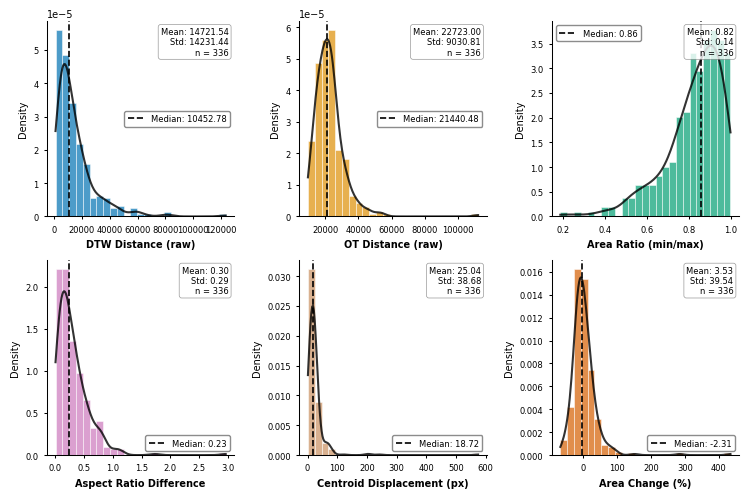

Analysis complete!
Generated files:
  - golden_standard_features.csv
  - golden_features_distributions.pdf


In [10]:
plot_feature_distributions(features_df, output_prefix='golden_features')

print("Analysis complete!")
print("Generated files:")
print("  - golden_standard_features.csv")
print("  - golden_features_distributions.pdf")
